In [1]:
import numpy as np

from scipy.ndimage import affine_transform

### my modules
from fast_volume_align_ot import utils, plots, transforms, distances, signals

In [2]:
def rotate_voxel_zyz(voxels, alpha, beta, gamma, order=1):
    """
    Rotate a 3D voxel array using ZYZ Euler angles.
    
    Parameters
    ----------
    voxels : np.ndarray
        3D voxel array (shape: [Z, Y, X]).
    alpha, beta, gamma : float
        Rotation angles (radians).
    order : int
        Interpolation order (0=nearest, 1=linear, etc.) for affine_transform.
    
    Returns
    -------
    rotated : np.ndarray
        Rotated voxel array, same shape as input.
    """
    assert voxels.ndim == 3, "Input must be a 3D voxel array"

    # Compute rotation matrix
    Rz1 = transforms.rotate_z(alpha)
    Ry = transforms.rotate_y(beta)
    Rz2 = transforms.rotate_z(gamma)
    R = Rz1 @ Ry @ Rz2

    # Center of the volume
    center = np.array(voxels.shape) / 2.0

    # Affine transform expects the inverse rotation
    R_inv = np.linalg.inv(R)

    # Compute offset so rotation is about the center
    offset = center - R_inv @ center

    # Apply affine transform
    rotated = affine_transform(
        voxels,
        R_inv,
        offset=offset,
        order=order,
        mode='constant',
        cval=0.0
    )
    return rotated

In [3]:
L = 65
sigma = 2

f = utils.generate_3d_triangle_gaussian_shape(L, sigma)

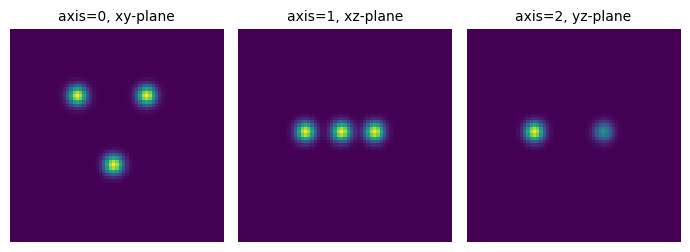

In [4]:
plots.orthogonal_2D_projection_plot(f)

In [11]:
alpha = np.deg2rad(45)
beta = np.deg2rad(0)
gamma = np.deg2rad(0)

f_rotate = rotate_voxel_zyz(f, alpha, beta, gamma, order=1)

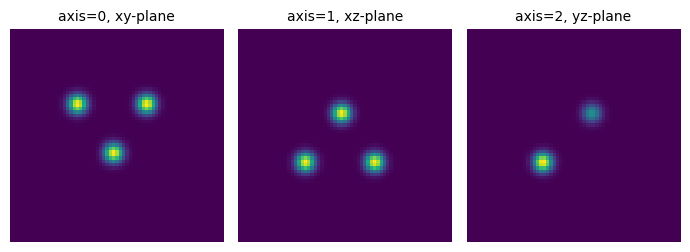

In [12]:
plots.orthogonal_2D_projection_plot(f_rotate)